# 2D Heat Equation modeling with Finite-Difference Method

## This notebook implements a simple two-dimensional heat-equation model,
This notebook implements a simple two-dimensional heat-equation model, using an explicit Euler time step and the standard five-point finite-difference Laplacian. The goal is to establish the model problem later used for the performance experiments in the companion notebooks.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Grid, stability parameter, and initial condition
For equal spacing in $x$ and $y$, the explicit update can be written with
$$
r = \frac{\alpha \Delta t}{\Delta x^2}
$$
For this 2D five-point scheme, a standard stability condition is $r\leq 1/4$. I use $r=0.2$. The initial temperature is one in a small square at the center of the domain and zero elsewhere.

In [3]:
# Spatial grid and physical parameters
N = 100
L = 1.0
alpha = 1.0

# Uniform spacing in both x and y directions
dx = L/(N - 1)

# For the 2D explicit scheme, r = alpha*dt/dx^2 must satisfy r <= 1/4
r = 0.2
dt = r*dx**2/alpha
print("dx =", dx)
print("dt =", dt)
print("r =", alpha * dt / dx**2)

# Initial condition: a hot square centered in an otherwise cold domain
u = np.zeros((N, N))
start = N//2 - 10
end = N//2 + 10
u[start:end, start:end] = 1.0

dx = 0.010101010101010102
dt = 2.0406081012141623e-05
r = 0.20000000000000004


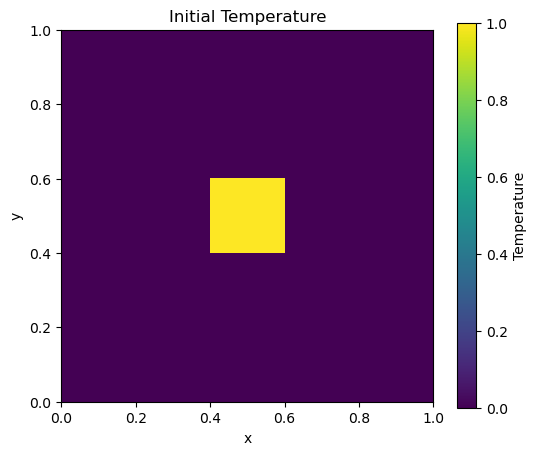

In [10]:
plt.figure(figsize=(6, 5))
plt.imshow(u, origin="lower", extent=[0, 1, 0, 1])
plt.colorbar(label="Temperature")
plt.title("Initial Temperature")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## 2. Finite-difference update
At each interior point, the Laplacian is approximated by the four neighboring grid values and the center value. The implementation below uses NumPy slicing so the whole interior stencil is evaluated without an explicit Python loop.

In [4]:
# One explicit Euler step using the 5-point finite-difference Laplacian.
# Boundary values are left unchanged, which corresponds here to fixed zero boundaries.
u_new = u.copy()
u_new[1:-1, 1:-1] = (
    u[1:-1, 1:-1] + r * 
    (
        u[2:, 1:-1]
        + u[:-2, 1:-1]
        + u[1:-1, 2:]
        + u[1:-1, :-2]
        - 4 * u[1:-1, 1:-1]
    )
)

## 3. Time integration
The solution is advanced for 500 time steps. Snapshots illustrate diffusion of the initial hot region while the boundary remains fixed at zero.

In [5]:
# Reinitialize the temperature field and advance the solution in time.
u = np.zeros((N, N))
u[start:end, start:end] = 1.0
n_steps = 500
snapshots = {}
for n in range(n_steps + 1):
    if n in [0, 100, 500]:
        snapshots[n] = u.copy()
    u_new = u.copy()
    u_new[1:-1, 1:-1] = (
        u[1:-1, 1:-1]
        + r * (
            u[2:, 1:-1]
            + u[:-2, 1:-1]
            + u[1:-1, 2:]
            + u[1:-1, :-2]
            - 4 * u[1:-1, 1:-1]
        )
    )
    u = u_new

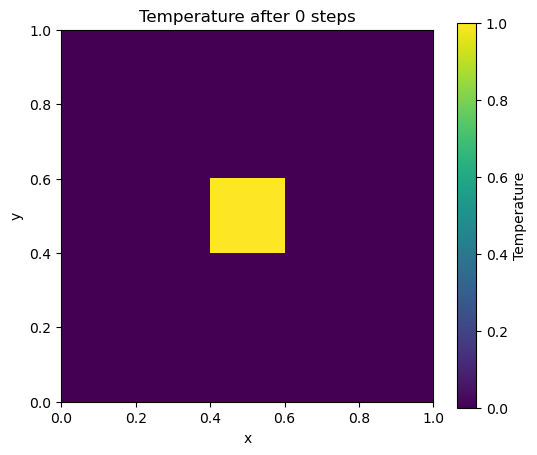

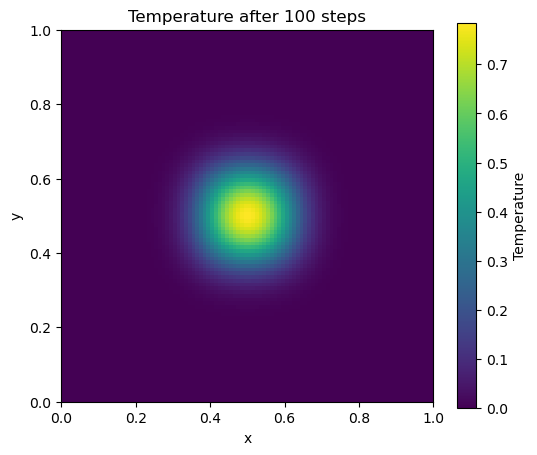

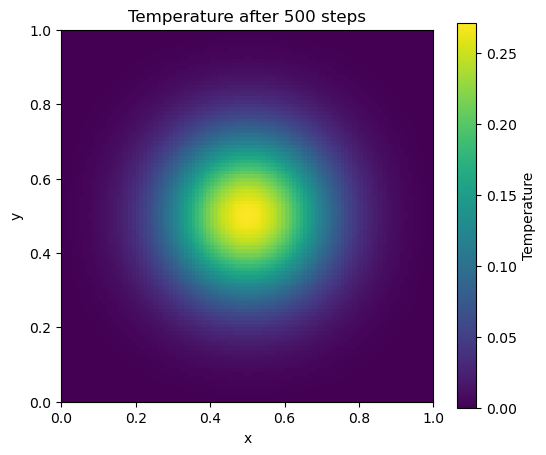

In [14]:
for step, data in snapshots.items():
    plt.figure(figsize=(6, 5))
    plt.imshow(
        data,
        origin="lower",
        extent=[0, 1, 0, 1]
    )
    plt.colorbar(label="Temperature")
    plt.title(f"Temperature after {step} steps")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()

## 4. A simple diagnostic
For a diffusive problem with fixed cold boundaries, the peak temperature should decay as heat spreads through the domain. The maximum-temperature history provides a quick qualitative check.

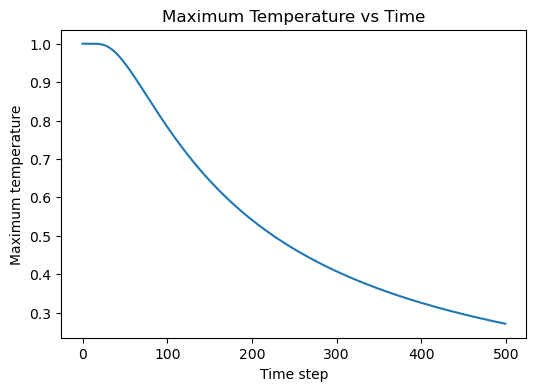

In [6]:
# Track a simple diagnostic: the maximum temperature over time.
u = np.zeros((N, N))
u[start:end, start:end] = 1.0
max_temp = []
for n in range(n_steps):
    max_temp.append(u.max())
    u_new = u.copy()
    u_new[1:-1, 1:-1] = (
        u[1:-1, 1:-1]
        + r * (
            u[2:, 1:-1]
            + u[:-2, 1:-1]
            + u[1:-1, 2:]
            + u[1:-1, :-2]
            - 4 * u[1:-1, 1:-1]
        )
    )
    u = u_new

plt.figure(figsize=(6, 4))
plt.plot(max_temp)
plt.xlabel("Time step")
plt.ylabel("Maximum temperature")
plt.title("Maximum Temperature vs Time")
plt.show()